# تصنيف حروف لغة الإشارة العربية باستخدام التعلم العميق — V5
### Arabic Sign Language Alphabet Classification

**تقرير فني تنفيذي — بنية النموذج، إجراءات المعالجة، مؤشرات الأداء، وسجل التدريب المعتمد**

| مؤشر الأداء | القيمة المسجلة |
|---|---:|
| الصور الصالحة | 7,653 |
| توزيع البيانات (تدريب / تحقق / اختبار) | 6,165 / 744 / 744 |
| عدد الفئات | 31 |
| دقة التحقق V5 | 90.19% (671/744) |
| دقة الاختبار V5 | 88.31% (657/744) |
| Macro F1 للاختبار | 88.24% |

**التصميم المعتمد:** `MobileNetV2 + EfficientNetV2B0 → Deep Features → PCA(128) → SVM/RBF → Ensemble`.

**ملاحظة منهجية:** المقاييس المسجلة استكشافية؛ لم يُضمن الفصل بين الأشخاص عبر مجموعات الصور، واستُخدمت مجموعة الاختبار في مقارنات سابقة. ويلزم تقييم مستقل على مشاركين جدد لإثبات التعميم.

## هيكل التقرير ومحاور التقييم

| المحور | الوزن |
|---|---:|
| معمارية CNN وأبعاد Tensor وحجم الشبكة | 20% |
| التدريب وتحليل منحنيات الدقة والخسارة | 15% |
| مصفوفة الالتباس ومقاييس التصنيف | 15% |
| الحفظ وقابلية إعادة الإنتاج | 10% |
| فحص البيانات والمعالجة المسبقة | 10% |
| التحسين المبني على الأدلة | 15% |
| التصميم وFine-Tuning | 15% |

**تنظيم التنفيذ:** القسم الأول يسترجع نموذج V5 ويعرض المخططات المحفوظة والتحليلات. القسم الثاني يوثّق خلايا التدريب الأصلية بصيغة قابلة للطي؛ ولا تُنفّذ عند اختيار `Run all`.

## 01. استعادة ملفات النموذج ونتائج التقييم

تحميل حزمة V5 والتحقق من اكتمال النماذج والتسميات وسجلات التقييم دون إعادة التدريب.

*مؤشر فني:* أحمال النماذج والتسميات وملفات التقييم؛ التحقق من سلامة الأرشيف.

In [ ]:
# تهيئة مكتبات التحليل واستعادة الملفات دون تحديث TensorFlow دون حاجة
import io, os, sys, csv, json, zipfile, hashlib, base64, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown

try:
    import joblib
    from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
    from sklearn.preprocessing import normalize
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "joblib", "scikit-learn"])
    import joblib
    from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
    from sklearn.preprocessing import normalize

from PIL import Image, ImageOps

WORK = Path('/content/ArSL_V5_Defense') if Path('/content').exists() else Path.cwd()/'ArSL_V5_Defense'
WORK.mkdir(parents=True, exist_ok=True)
FIGDIR=WORK/'figures'; FIGDIR.mkdir(exist_ok=True)
REQUIRED={'model_0.keras','model_1.keras','v5_classifier.joblib',
          'labels.json','inference_config.json','metrics_v5.json','class_comparison.csv','validation_candidates.csv'}

candidates = [Path('/content/ArSL_V5_Final_Results.zip'), Path.cwd()/'ArSL_V5_Final_Results.zip']
source = next((p for p in candidates if p.is_file()), None)
extra_images=[]
if source is None:
    try:
        from google.colab import files
    except ImportError as e:
        raise RuntimeError('هذا الدفتر مصمم للتشغيل في Google Colab. أضف ملف ZIP إلى مجلد العمل عند التشغيل المحلي.') from e
    print('ارفع ArSL_V5_Final_Results.zip، ويمكن إضافة صورة يد اختيارياً في الاختيار نفسه.')
    uploaded=files.upload()  # خطوة تفاعلية واحدة فقط عند Run all
    for name in uploaded:
        if name.lower().endswith('.zip'):
            with zipfile.ZipFile(name) as z:
                if REQUIRED.issubset(set(z.namelist())):
                    source=Path(name); break
    extra_images=[Path(name) for name in uploaded if name.lower().endswith(('.jpg','.jpeg','.png','.webp'))]
if source is None:
    raise FileNotFoundError('لم أجد ملف نتائج V5 الصحيح. أعد التشغيل وارفع ArSL_V5_Final_Results.zip')
with zipfile.ZipFile(source) as z:
    names=set(z.namelist())
    missing=REQUIRED-names
    if missing: raise ValueError('ملفات ناقصة من الحزمة: '+str(missing))
    if z.testzip() is not None: raise ValueError('الأرشيف تالف؛ أعد تحميله')
    for name in REQUIRED:
        (WORK/name).write_bytes(z.read(name))  # أسماء معروفة فقط؛ لا نفك الملفات غير الموثوقة
    # لا يلزم تنزيل الصور الأصلية لعرض نتائج التدريب المحفوظة

labels=json.loads((WORK/'labels.json').read_text(encoding='utf-8'))
config=json.loads((WORK/'inference_config.json').read_text(encoding='utf-8'))
metrics=json.loads((WORK/'metrics_v5.json').read_text(encoding='utf-8'))
classes=labels['class_names']; ar=labels['arabic_labels']
comparison=pd.read_csv(WORK/'class_comparison.csv')
candidates=pd.read_csv(WORK/'validation_candidates.csv')
assert len(classes)==31 and config['class_count']==31
print('الحزمة جاهزة ✓ | عدد الفئات:',len(classes),'| طريقة الدمج:',config['mode'])
print('المجلد:',WORK)

## 02. فحص توزيع البيانات

عرض أعداد الصور في مجموعات التدريب والتحقق والاختبار وفق التقسيم المرجعي المحفوظ.

*مؤشر فني:* 6165 تدريب، 744 تحقق، 744 اختبار؛ فئات التصنيف: 31.

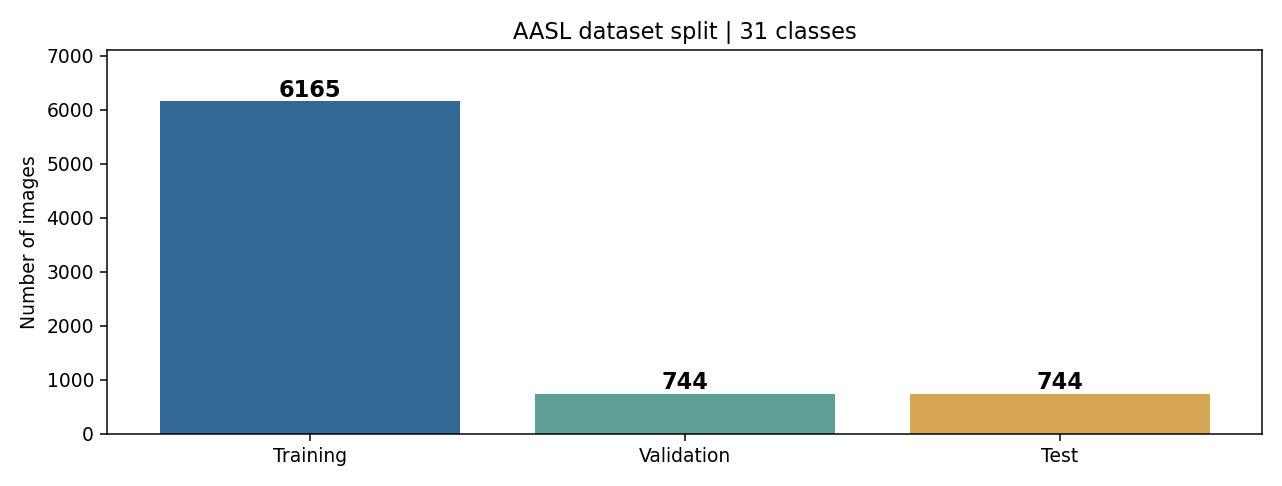

In [ ]:
# رسم يوضح أحجام مجموعات البيانات، ولا ينشئ صوراً تدريبية جديدة
counts={'Train':6165,'Validation':744,'Test':744}
fig,ax=plt.subplots(figsize=(9,3.5))
bars=ax.bar(counts.keys(),counts.values())
for b,v in zip(bars,counts.values()):
    ax.text(b.get_x()+b.get_width()/2,v+65,str(v),ha='center',fontsize=12)
ax.set_ylim(0,7200); ax.set_ylabel('Number of images')
ax.set_title('Dataset split used for V5 (31 classes)')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout();fig.savefig(FIGDIR/'01_dataset_split.png',dpi=155);plt.show()
print('المعالجة: Decode RGB  →  Resize with padding  →  CNN internal preprocessing')
print('التقسيم على مستوى الصورة؛ لم نضمن فصل أصحاب الإشارات بين المجموعات.')

## 03. هندسة CNN وأبعاد Tensor

استعادة معماريتي MobileNetV2 وEfficientNetV2B0 وعرض أبعاد الإدخال والميزات والمخرجات وعدد المعلمات.

*مؤشر فني:* MobileNetV2: 160×160×3؛ EfficientNetV2B0: 192×192×3؛ المتجه المستخلص: 1280.

In [ ]:
# تحميل المعمارية والأوزان وإحصاء الأبعاد والمعلمات
import tensorflow as tf
models=[]
for i in range(2):
    models.append(tf.keras.models.load_model(str(WORK/f'model_{i}.keras'), compile=False))
rows=[]
for i,m in enumerate(models):
    gap=m.get_layer('global_average_pooling2d')
    # هذا المتجه مستخرج من الطبقة السابقة لتصنيف الحروف
    rows.append({'CNN':['MobileNetV2','EfficientNetV2B0'][i],
                 'Input tensor':str(m.input_shape),
                 'GAP tensor':str(tuple(gap.output.shape)),
                 'Output tensor':str(m.output_shape),
                 'Parameters':int(m.count_params()),
                 'File MiB':round((WORK/f'model_{i}.keras').stat().st_size/2**20,2)})
shape_df=pd.DataFrame(rows)
display(shape_df)
for m in models:
    assert m.output_shape[-1]==31

## 04. مخطط نظام التصنيف النهائي

تمثيل مسار الصورة من الشبكتين إلى متجهات الميزات ثم PCA وSVM ودمج التوقعات.

*مؤشر فني:* 2×1280 → 2560 → PCA(128) → SVM → 31 فئة.

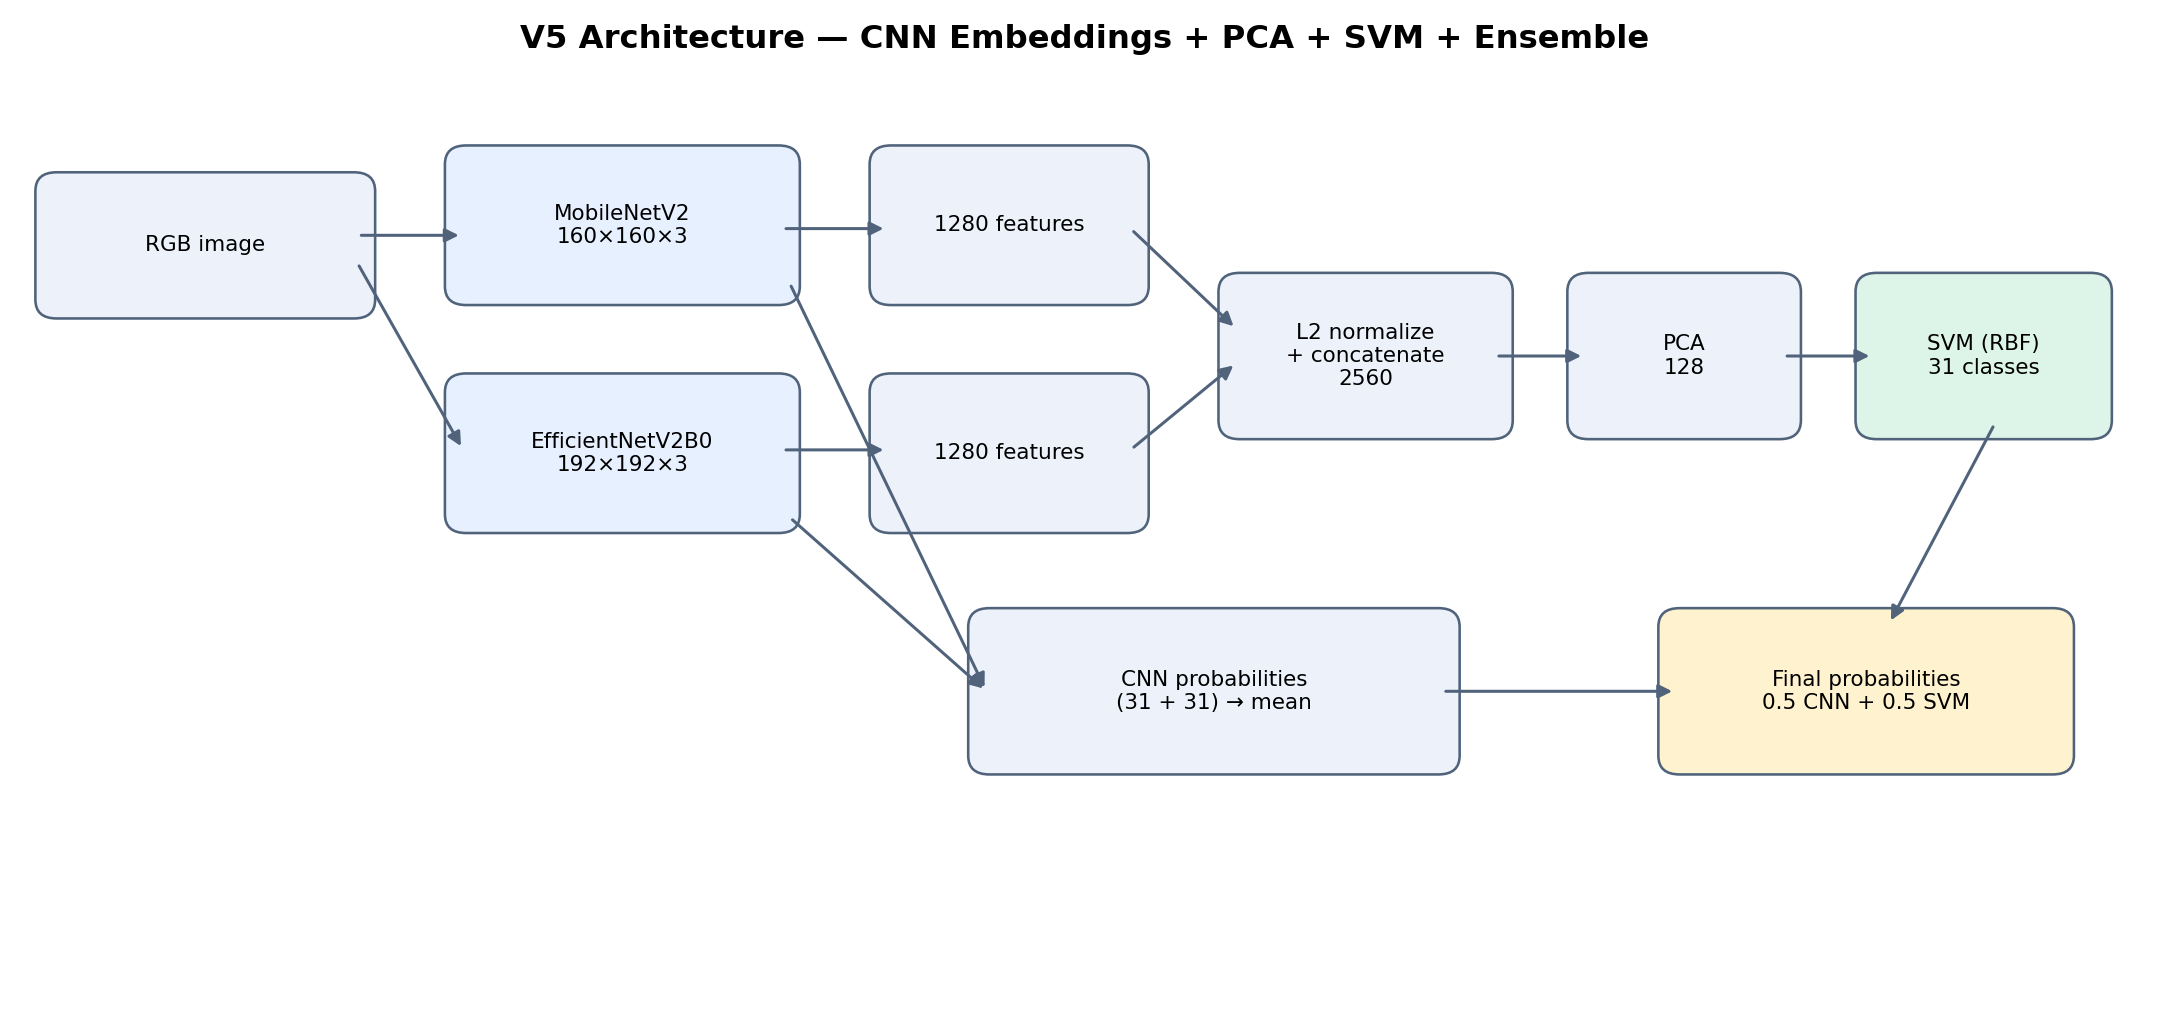

In [ ]:
# مخطط مرسوم برمجياً لتسلسل Tensor والاحتمالات (لا يعيد التدريب)
fig,ax=plt.subplots(figsize=(14,6.6));ax.set_xlim(0,14);ax.set_ylim(0,7);ax.axis('off')
def box(x,y,w,h,s,color='#EDF2FA',fontsize=10):
    p=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12,rounding_size=0.14',
                     lw=1.2,ec='#50637B',fc=color)
    ax.add_patch(p);ax.text(x+w/2,y+h/2,s,ha='center',va='center',fontsize=fontsize)
def arr(x,y,x2,y2):
    ax.add_patch(FancyArrowPatch((x,y),(x2,y2),arrowstyle='-|>',mutation_scale=13,linewidth=1.4,color='#50637B'))
box(.2,5.2,2,.85,'RGB image')
box(2.9,5.3,2.1,.95,'MobileNetV2\n160×160×3', '#E7F0FF')
box(2.9,3.6,2.1,.95,'EfficientNetV2B0\n192×192×3', '#E7F0FF')
box(5.7,5.3,1.6,.95,'1280 features')
box(5.7,3.6,1.6,.95,'1280 features')
box(8,4.3,1.7,1,'L2 normalize\n+ concatenate\n2560')
box(10.3,4.3,1.3,1,'PCA\n128')
box(12.2,4.3,1.45,1,'SVM (RBF)\n31 classes','#DDF4E8')
box(6.35,1.8,3,1,'CNN probabilities\n(31 + 31) → mean')
box(10.9,1.8,2.5,1,'Final probabilities\n0.5 CNN + 0.5 SVM','#FFF2CE')
arr(2.2,5.7,2.9,5.7);arr(2.2,5.5,2.9,4.1)
arr(5,5.75,5.7,5.75);arr(5,4.1,5.7,4.1)
arr(7.3,5.75,8,5);arr(7.3,4.1,8,4.75)
arr(9.7,4.8,10.3,4.8);arr(11.6,4.8,12.2,4.8)
arr(5.05,5.35,6.35,2.3);arr(5.05,3.6,6.35,2.3)
arr(13.0,4.3,12.3,2.8);arr(9.35,2.3,10.9,2.3)
ax.set_title('V5 Architecture — CNN Embeddings + PCA + SVM + Ensemble',fontsize=15,weight='bold')
fig.tight_layout();fig.savefig(FIGDIR/'02_architecture.png',dpi=155);plt.show()

## 05. منحنيات التدريب والضبط الدقيق

عرض Training/Validation Accuracy وTraining/Validation Loss لكل شبكة اعتماداً على السجلات المحفوظة.

*مؤشر فني:* المنحنيات تخص Fine-Tuning السابق الذي اعتمد عليه V5.

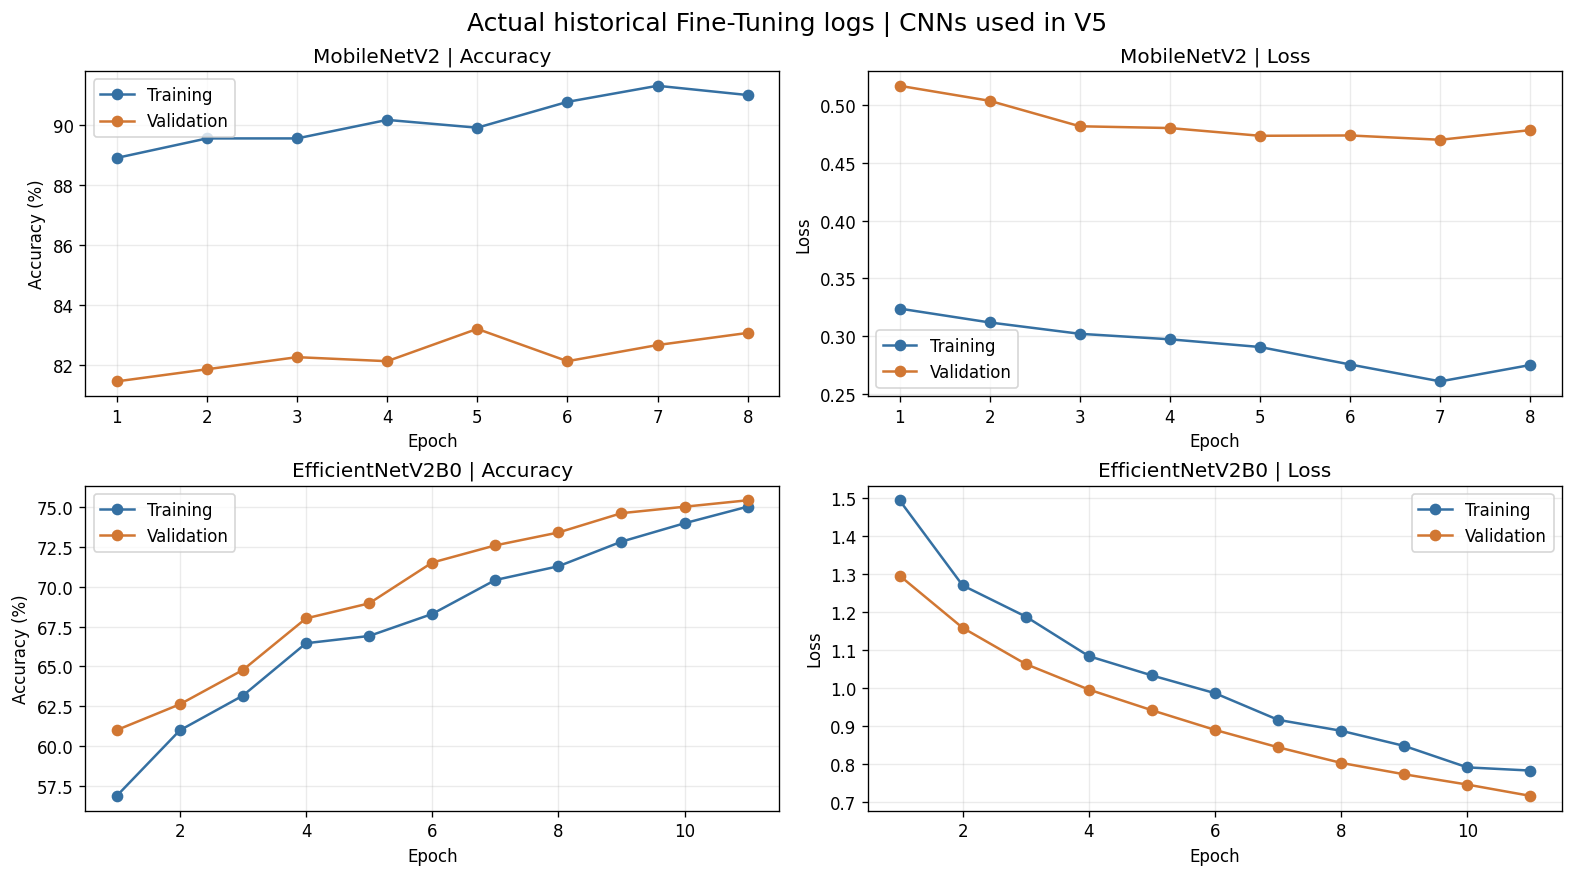

In [ ]:
# منحنيات التدريب الحقيقية من ملف V3 السابق، مضمّنة لتعمل دون رفع V3
HISTORY_CSV=json.loads(zlib.decompress(base64.b64decode("eNqtlutqXEcQhF8l6Pdm6dt0z+RZDEJR1rHAkYIkG0zIu+frWVYkgZUJZEFCOttnqi9V1fPHzW9PPz98Pt3+9vR8uv348Hh6/fJ4+uX208PL69Pzt+P9y9ebn364Of3+dP/pcHd//+X57v7b4fPp7vnx4fHX2+e719Ph89PLy+Hr3efbt+/7n3764fnDoxzkOM+fNYZqWtnBj7I/KqlqI/P0oySBbj5H6ZhhFiXa72oMTbVSWcOqo4aW5FzT1MJtZsPs0DW8StYaGiKEXoVRna7L1H2JD/GNM0dMn8qJY9psHAkhEZm6otyqcew/4Yiu5SkzigMopF82G1PSx4hKr8WjAIBnQgZGOqNxOqUlOkJWJ7j6m6s4too0K3NEeJjExlHzHEOmFG+fcSQ0dJdTVOUNtGPXXDFoqYmC/w6ODA+VOat07lbQRl6zWTbCvbOm0pKaM8CWFXs6Y1dTI6g93XKspddRanh6xDAynXatmPI1M7roVRWzYfrtpdbzadpIDn8HJqWAgmejYJ2dh5NQDaZybC7XjSMW1J0TFopq49QuZ9HBSM9Zc2W9U04wnqwyl+mxcrdNEloHJQxyP7eNzgwV44fSz2y7OaC9jx8f7h9Oj69o86vdfjrdfVee3xUkOcpEiAwtsnXmR3CnwKKEbME8O3ObwQBtWToT55kdlzkJrxJxpW1+0V4XTEdmMniIBBPsWAwSfc0cTMM6yhGD6UDNBCFoggYNQIe+UoO3LxrjichcxM6xjL4RGrUUfeQwze5fd41eZbNXGss7Q28FV9HpOWhoXtQUDM+pNzKUvzpBG2M44lmrz+wYa52iDyYGRVej6oAAJOfNfFAvouEgqqM3ExWbasfC9+iUa5Lm8h0GdxY+kQgfZWZH0ahs6sqAORd9UJ3zJodxoHge9LiK+ihQ6SGqi+19KKMNhYZNGN5REthRpHBCoZyLElBL1sSCQK3uoB6RqfAWWY5+3G0ZFAC1V8PDBOuotohFLGNmdBfGI5GJ7HnMmZqDSMSIIGES1MZ8tmli8j0MpgFBrM8rh89Cr7BdGu1XmN3b539ePAwBV0XTqzAeurWOa3/ajyH0sC1SZUpBcd4CKCjfhdBxqCrZuoQz3T5bGb2g6BXLKN4WD6EYBD4CG6DiugpjLK7KYCdElEYPNC3/PlElSiGMYfiTjcSpftFE0lH0h+Mx0Vx2FUYxaGuN8whN9fCgW4s5hOwzOogdVGgQV0IGevabJgTMRJPsrVDWQc2rKOSM6M8MEI+NAt3+MXx8cmU7PmulT4y3ncOb0mduE1W/juK4zGrRzsp9Ivby7xsBjsW/tJRyAHrTFKLrVqCgYN3WNRQOgNm4HTuGnbFWw3ANYdsRpiSPwvaeFMYycPMEx8dFacVe9WRkIW7UeR2Gmwsbotrggek9Vvs6EG2I3c1GCRY1lA2XEQjxoj8yLOcWQdFoGD1fQ+GqZThZp8iG2UuZFyc3FtY1/o3SO0ockoRhqkxBdjFzJ9Ru3d5OU9mL12GijQopMEPY30OlMFYhv/EdyLaP4yVaj/+3341dza4butMqhrmweJ1XYcivKw6mg3nvW0eNjZV9CbHWZ1/othhlfytc3Fj9fY+Md4beLl19bYreaLEfjR4ha9HwxzHOPEjcAydhUtjy5tbNn38BioSOEw==")).decode('utf8'))
# نعرض منحنيات التدريب والتحقق لكل شبكة على حدة، لا نقارن الشبكتين بخطين مضللين
# هذه السجلات محفوظة من Fine-Tuning في V3 (الأساس الذي استخدمه V5)
networks = [
    ('mobile_more_finetuned_history.csv', 'MobileNetV2', 'mobile'),
    ('efficientnetv2_fine_history.csv', 'EfficientNetV2B0', 'efficientnet'),
]
for file_name, model_name, file_tag in networks:
    history = pd.read_csv(io.StringIO(HISTORY_CSV[file_name]))
    epochs = np.arange(1, len(history) + 1)
    # 1) Training Accuracy مقابل Validation Accuracy للنموذج نفسه
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(epochs, history['accuracy'] * 100, 'o-', label='Training Accuracy')
    ax.plot(epochs, history['val_accuracy'] * 100, 'o-', label='Validation Accuracy')
    ax.set(title=f'{model_name} — Accuracy (V3 fine-tuning)', xlabel='Epoch', ylabel='Accuracy (%)')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(FIGDIR/f'03_{file_tag}_accuracy.png', dpi=165)
    plt.show()
    # 2) Training Loss مقابل Validation Loss للنموذج نفسه
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(epochs, history['loss'], 'o-', label='Training Loss')
    ax.plot(epochs, history['val_loss'], 'o-', label='Validation Loss')
    ax.set(title=f'{model_name} — Loss (V3 fine-tuning)', xlabel='Epoch', ylabel='Categorical cross-entropy')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(FIGDIR/f'04_{file_tag}_loss.png', dpi=165)
    plt.show()
    i = int(history['val_accuracy'].idxmax())
    print(f'{model_name}: أفضل Validation Accuracy = {history.loc[i,"val_accuracy"]*100:.2f}% في الجولة {i+1}.')
print('ملاحظة: لا يلزم تطابق Training وValidation؛ المهم الفجوة والاتجاه العام. هذه منحنيات V3 وليست تدريب SVM في V5.')

## 06. مصفوفة الالتباس ومقاييس الأداء

تحليل مصفوفة الالتباس المتاحة من V3 ومقاييس نتائج V5 الموثقة مع الفصل الواضح بين المصدرين.

*مؤشر فني:* مصفوفة الالتباس المعروضة: V3؛ دقة V5: 88.31% اختبار استكشافي.

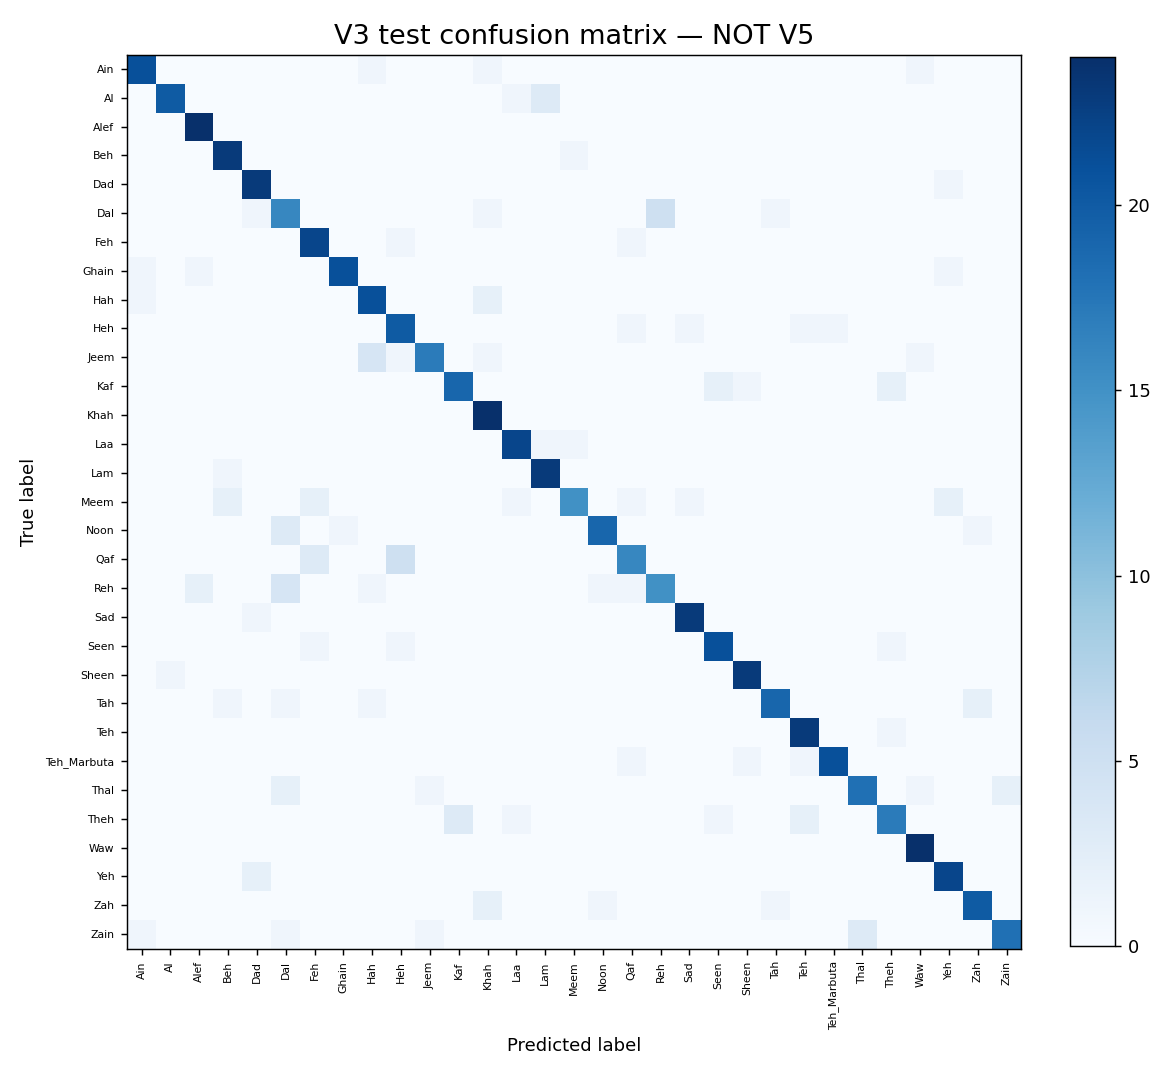

In [ ]:
# مصفوفة الالتباس المحفوظة للإصدار V3؛ لا تُنسب إلى V5
V3_PRED_CSV=zlib.decompress(base64.b64decode("eNpVmkuyLLcNROe9lg4F/yBX44H0HKGJ7FDI+/dJ/sArv4G7b3UVCSQyE2D98/f/fv3rzz++//371x9//v7Prz/04ff//PXvP//49dfvvz72tW/4rebQzeyT+pd/4bcRah45t0+yb9IFY8QxRm+fmL78C79Zsh6afeI38qlzde/lk9o3ZT7nOmoPfX4OfE4thZRL/cT+jXpA6iPFHHhA+fKPO7TMV+OTv/r9qKX08Unxm+J8eu+j8Hl8+cfFPQfj9tG+cS4/9Vpz//CoeXUJTbf+aqEsWistnxi+UX82i6Pk+OnfuVPunCx/WPZc+eDS3GrbGxvso9de775HzLFlrg9rZz2NPnr8xPKN2keO3UrJn1i/jY9l1Jh7S+9WRmr5LG4Mq8Q98jT9tdVe9Nc4vlEbHTmOlOfd+MfTjM1Za/eLEQmtlfbJrEdf1NC7EceTyV6sVJvr1Q2T2Yi1zN/rc+7ZMjfYoSvZ2EzaWegWczMelr9xfo4pVWGgfePcXLUyQsh6eJ6h5eE98QVLWavJLZUGjs6G+gg99/p80Qk3ETjZsBostnsD67HGMBw4pI5MD66f6zWrLCkLaHOJucRSY73p7Ip/7L6FEthTUsBnOlIJPZRkBzrakAGWvRxAF2+yemsqi/LkcuRU00SWLsgtW4mC2k5n5WGV7wTUGbDcWqYO9u3BbOkK8FltTZSRwLWLwgByzoCHBcyiy2Yh2FOVI6U4LhhZbquFFZ5o9WF9xOjoTb3UkDw8lSrUDhbYS7NcPXgtWKZIDziGUmO3cIw/p1MnRIbAkde7VOul1+CZLBZDr1RG/WprxGlQZ+kiuWUyVx/oR0qRMj01XiL8kVP3C0z/axd8hC4NpXanekAhYKfcUusRRmssf4aidjitODIGoY1jElqZywmpW/dIgRzwX+4GK4lJoVzkEtrWb6iAeYuL/2biAWmCoE4egFEifPfhRllBNTNxE0k5VvZzbgcq2Q2w9uvZW8qVYM7YRiqRQttsPlp/yNM67Di6x8kKkYy3iithaMrUfnYN8EWLF0MNjLGUejdj8Fmu3akbiEDfR0pYWhKj1PXzPBlvPIkFgXDwp82SaNRLU5a4uE7+1M64W5kwgRBaBSU8aKEgiILq3QwISan3/WwW1iM1d3LSahSVc2VdQSVL7UUM9QSf3Ho18BIrV5ytCnAWDgGQQ0A4rpKMHKIFsnYwji4lQXKLYshwe518Me8ezVC5S81sG/KN5dGWwPaezyhLgy02GzdLZGkLJHA5IQK4NUe7y+rkv/LtQQNai0Bq15MyI0iynjd0gGlu4teTnYB61eichABSp2Xmc0IzxgJJeRA66CEjK53ICY/2IrQ8GlWVr3ST+1zSeXhkJQrAFs/R5uUuH7B7HiKRw7g8bEj+9g8M/g5PESNALaUDrVobVsC1JYOAfH9bSxxTKvbDWsMFpeqLQSlTXeQ9sddAF6Th+tfh4qLlrQdAEehd8chRN5YuX3IvtOhydSPQxlrPzXgcdbmUXU9LFU6NhOqioQG2PE5WIwQ0wO4GARWOUFydgY4zyDlQSwAPIUo/lAPSuGmBFODzfG0Ee4UX7uXi/RDcFTVkv9vl7lrjNG8nDU3UOSF5YtnlMlTlW2ggvHwYY2CwikTpFF1jNcmOhWqlc/eHP6DhKIJxoieNStRKO5iJxfK9XQdjKd+taNvyfP7zlqhEpXUjulUcgDtdSMQgheK0EeWhrmOIk5xPkcpelHIjUwgEDDIzM9bnJsZZS0WDgNB1qlAHhFP3rRBQ3CMrvwAYiH8fj/VM2nY9koVz7FjZ48lhCHj7UGMFAC0e1pWBjtldFVgbspmbBwd8ckwgQCA7VNHZPqpeSnIgU9EqSoWvz4pH2MrjzbHbTa7iAJVoluAeqZNOJOamC8MDSZan7CBkjFZ7LDMW/MKhoS14g+YP5H5RzchtVbBw0OhhvARdBSC2F8Tje3+jTArhkNeyUpnTsu4HdAQSBPgOyqC7GVcPiSVGr/+wacYizZ+Bz4bpb7tE7eUQZFOXCLI6QOm61EKMEV0+RKPmB+06KMJ3VOnG8zzsg9UNBFxVsC5rtREPvgFtvKxKQJDN8VTrWt7+OQmsddzt8xHRskmc06JDHII8RDNRSPZl2K+HhZKR86P2qp3xGbMYCApOws6nJkfZnVTw7eTCHRdx16MfBcxPZ1HxT6kWVzJp+TQe2xvQ3+awyn7CAKnBJ6XHPAN17MjGBf+3qLM4sMdjwQTa594Y6lBGfvworJsfSu1SL3u8hCW6bFfzAvCaOxmaVJTMKXuQ1ijGPrdj92k8jSg9upqxqzYgSMT5oKCKEU7FYy1Ku/Yhwc7JH1ZxFtyu3TQR56mNjqiS1Hjsh9ElYu/t5ByE5dlV3bWpjZZlPPKipk0Uf9o6Gco+/fEEOM6MBj+4QeZpAUryXotQkfF6HLFKtmoBkxOIWy7l6SV6lo9xoaYxmC7yKjNwt4d40afShZS0hhVQdH+6JI0vcMS3lcFRI5bXZuJ5gvzw3qx8A73QIXlwV6YAedeIwT7DCnrf1d/ujXc2WlWsFzbATiu61ctCMxJ0rD81Euig37Tn8Qw0Gh1gmJ5pc7160IFQaL3L0dHmVxvJW62CPubkFg+jggYLuqt0ApUb+MGWQFpakfQxddxK/cPeH0IDUny0RGPICos3uQWrMkSGOxdyOfngtJj8ajsUAS+b+uMz3Bj6aO4PyRRij1aXjesAFJLdURC+hNCMtU0YOcXZbp+etcqBuXjzMWD53aLJ2j4OslOwQYL9lklezmVNI+YsJjqDQTFwhFNOgGqhxLM+GjE6kpPZhuOC9o9L4kLcgdMhPyav3buPioxgfE6wkKxU1O44YSFDaiHueEJ8eYVZzYo9LWqUysQtAobj6xD37iGAVJM12cVIP8mtbsuGmZs+daaARcV2Zwhq9zBrh5NDVZfNp1UKMSaFb28YttcC7vJh06CR4e6u6qDq0uFT5I4+cvhuWwuwXzCv8TTndMfikBfdwJPNbouJUk5yOsnP5WkXBx1DmHCY+QlC7polrXCaCuOHx8bw+2xJdW6LQ9uEn1oAWGvsOmhRU9F8CZu+y+72aKNTeCeidGF7HDENflI3cFIPcPXwepAgIxib3b5Idz52KFdxY3+GTjIbQvlyrHQdLHu4UA0pRTwtHA1eyXl4/47TKlHe5RQNvJ+vW5bZ7i8XIrPTwp4YqumRVVmoU6PxIh7nF+62IA2SXO4MWj4tHhaiWS5Ff/R0JtJ7RyR007W/LrbUMPX1SiJmBJXzSQOuJsrHanS4fDBkI2tznWvUT+wulz4CG+ZdURdEa3MfJlusZnUNZqkamXsHD4F7RsPwGGiZvnnpggYnw0dM6vqbfNiuSZmZkHeoyoAWqwZSaWlUlnuYk+cjkR1jXuMVsYxC2I9uWNM//zuakeDGU6wl8R9m46wWXolmD2hM04/oU3jBMyafmyOaIYaTPaAMt/3UTErFp4kUt8jbnPzIHmvynrSYRpf9ETH9l90wsRrou7RLW2mEvEbrec1J0GFWfLwqXATlnP3iHk1TlAuvJstzzCkdifGxPrnPWfFxA1XrrJLrmCRVVwQl0W28Go6Bqm7B5VDIPZHLK/hBZvm0YBQgbuoUaIOpBaRNDZHEhievtIJQfXWFpZrdSfWI1WddJ0Y6nxinjQdSEHI/kz76bsQtPcO5Tl/R0uwU5hfIWYuPgHI/KqA+q0FxZdlvEWKSk40Jm1kWZCzOSceeyMFUGrEcumCxSvmhHtanKcayaSg7ORvlrkbX0hc5yHKKdHqX2PrQLH/FBVnuOipRYLaspaBxzxm5pElV0ZvzWnRk5vjQXHH69VPgJBTHeyy37H4qtwBAB794ugf8ZBZLn5ZPvOnDo6YTLRG+H5PQxbq204tATbp8DVFJTJNnPBNcXFHXMcFpZaimUh7TRinYcjZ3Wq7h1VV1PFjr7qPUPnSrrl3hbYRMnVbxRgmmps5Gu4pT6WRI6q4FinjUp3JI0lAhXs8HVWk7DiKdms2JwPkiyL+qmdjJkIsrc4hwG4TQZvmVfSykAMwp546nISYas24sNU3k+20ADGkY0a9GhnjCY1STjGp53RVNg2IS17FckQg/ZxNESFMEJ//QNfk50kO8u9qznS6YOJJTz76lBoF2P7lriHqLP85TaYA+iy40sOo66zhGEKOEf1s1JceqaMftaBGpVLy70DSeUPgXwpnFg2IcShrpdhoaK8U0HLY6mhTHriezSnTqc0q9Iag+xoYA0fSzRuhv0u/u1bEFlv2+aox7ffYLhY3lQlZ3qe42pAeCGO8xZxpHu/uitjuE0mGT9LPuQ2QQ0uYPTruugKdDFxp+6ph2k0cWHEK96ku4s6zK7Qu4YIxnPqRB+Ow0DpNpgFOfxkEnkWXOHub+dYLT6jObMPrr+n4hIhwlv0w7T5Su65OXis5fjVvizp9TBcGk1Han6UAsPWeDmJlpn1bR2mSQU9E6ZdSgx8cNmHlN0Pa9QX+KzccDiEQy7fcCRfIebiska57r6w66heAtrtS09/icIs8J1xMOFBLgHUdMrImF44WWGu3yXoL106Y8k9cOcuvw1qKF26NqOjxs3K2rp8uT19eLD+gfxtWRlSUT5Q7Bhs5I/cCflVmz/nAbPj7H53h/dhnukXWGOg/c7xkV7Nl80lPUyWuau2bMhr4GN7mUDXlpc6NT1cBp0ChgB95w9wp025PQpDmRO1wTaY38mFgNlcKxWAiu9ei6AJyoGVedoX7XJ3oa0+d+IQVE6pwI1XXzqhcx4ng6OM3L4vMqho7P1FzcOU7WwUH8MZdt8wm3iC2U8cwQeajeMznjg57SjxkWHXq5RyYlxXU+vafxKAyx8yGUUAEq8/MOTCUb3XUTC7E8+KGFpDb7toBdhnWOB9a5bLWqhuY5YIdeD13OVsP80IJuvcm5nWMK/paGnRkuYp5N/YEzc1R8nXAyTO+Ei7gjWP36wKgR2fsaQhzP6QJOObHSMnVgOgDssebbhywBxnuco8bHrQuGNJz3grBQTQeuu2w1eGoPa+okQYA42Kd9V5CfgGadVt4eChfe1YFvSqPwqk46/SgCVdcI9hzYSpTNB31Fc7AlZ9Mr6/Al+rhIApXWrtPGd1eC/DBTpXoHZXo1JPk7TqPr/GZO1ebaKcUAQT/lIt8+fAiZZDLO0FFHlazezyxYWbD0nNnDHPG++EHvFmP3U1r6xUZ/dNpHOt0w0XAKp6t361OP1jF5MY2evddSpM0P8SHBttzIOiCZPf7lsEad335l6DUR4eE8TIMcvnEpVic87DQ7Gr126y4uhDQ3nT2ecwCqJj7D2hbnaMSRnqaP3xMpNp10SrB7BmBLF5Ffbxk0ZTqcQ48ba+jPGzuo7D2ax0LGOr3qEQ6M4uz78o4UUdVrL8+YAoZdo/eDWQg96oDxnkchu7DUmS4Pmy9AqdZWn8ACyYf2t1LZpru4XpwVz5fjxn6NRdPjyUrHaupQsT+gN1M/6VZSTlODtBOBBBLi09kDPdlNx1KUhsV2h/0Fz5c0gD5ebkzzdgfexZqahxvymvQWgY+I6OKTxrZjW1CchzTOvRtWYvT3IEQpel4iwGl38wUOzd3CgsQaqYdAy/zKmM1zqlWoVYJuj/jT/PjqsQktvqVSNaZJ/kYW0K2aO16vA/3l+wIcWJ90dw+f9Q5V9dNJTOXQVNejgQKOORU98ECW5nHB6QV0trjwNGcFejlkvd2zno4GxVcSFdruHAq69A6g+csmaPLzOJGuDu/vWxUEv5wX3OSE9HLJ3SsUBrX7wT/2QbbuKhr2o7+vDVir0Y+WG75db2js3n+qeWq3Ja86xnhfrSzZRyhcPWblbc2RPw92DKDpPZR+zsrmVF82gJitmWbEenQ/ARaAY/v5fuqcJBzhGBqOpcd54PYxzE/DITMwxWvfcmDD4J77tprGpMOlht9izNYjVhHp5aVxfZxOrJ63PnHD6uGfItLRYB53Vsrd++MddGaSnlfEhlziM5XFxWmEdM8qK5zpEo03rppVnHMHvaybn9aCxc+D1etzdD70gBxhDHMyft4RIv5WvPvVMGPOCp+T1jDuO0eNbnnC4pQgfBF8kDd772nc7jRN2vrDpqpfe09KhsaZzztOTUch2ccf88RD48pzxeQMKZ7Kbr2uqHFgeF8WRYLbPa/ow+6rnnOVOoKt+Qfp8F98zraAWCOl/wfsN5xS")).decode('utf8')
v3pred=pd.read_csv(io.StringIO(V3_PRED_CSV))
cm=confusion_matrix(v3pred['true_id'],v3pred['predicted_id'],labels=list(range(31)))
fig,ax=plt.subplots(figsize=(10,8.5));im=ax.imshow(cm,cmap='Blues',interpolation='nearest')
ax.set_xticks(range(31),classes,rotation=90,fontsize=6)
ax.set_yticks(range(31),classes,fontsize=6)
ax.set_xlabel('Predicted class');ax.set_ylabel('True class')
ax.set_title('ACTUAL Confusion Matrix — V3 test (NOT V5)')
fig.colorbar(im,ax=ax,shrink=.7);fig.tight_layout();fig.savefig(FIGDIR/'04_confusion_matrix_V3_ONLY.png',dpi=155);plt.show()
errors=cm.copy();np.fill_diagonal(errors,0)
ix=np.dstack(np.unravel_index(np.argsort(errors.ravel())[::-1],errors.shape))[0]
most=[(ar[classes[i]],ar[classes[j]],int(errors[i,j])) for i,j in ix if errors[i,j]>0][:5]
print('أبرز التباسات V3: (الحرف الحقيقي، الحرف المتوقّع، عدد الصور)')
for row in most: print(row)
print('V3 correct:',int(cm.trace()),'/',int(cm.sum()))

## 07. نتائج الفئات على بيانات التحقق

عرض عدد التصنيفات الصحيحة لكل فئة ومقارنة النتائج المرجعية بالإصدار V5.

*مؤشر فني:* المقارنة على Validation؛ لا تمثل مصفوفة الالتباس الكاملة لـ V5.

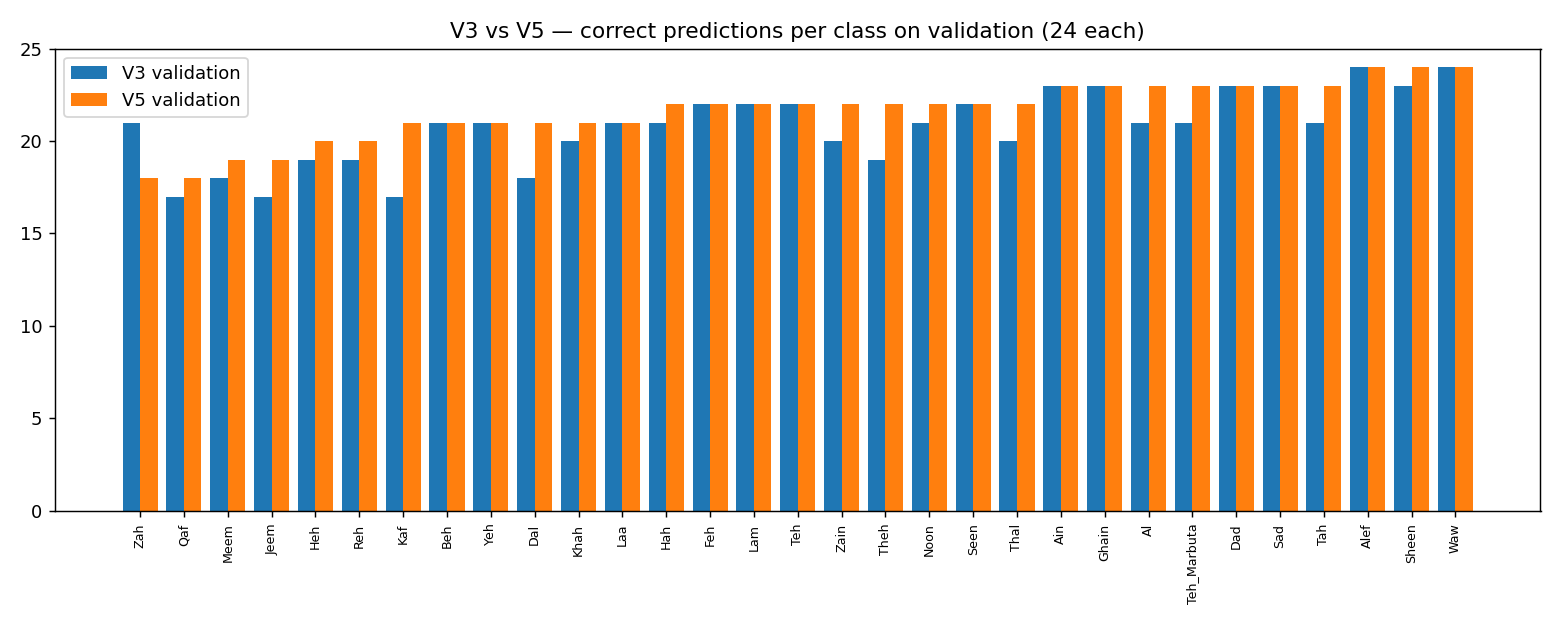

In [ ]:
# هذه مؤشرات V5 الحقيقية للفئات، ولكنها تخص Validation (لا تُسمى Confusion Matrix)
df=comparison.sort_values('V5_correct')
fig,ax=plt.subplots(figsize=(13,5))
x=np.arange(len(df)); ax.bar(x-.19,df.V3_correct,width=.38,label='V3 correct')
ax.bar(x+.19,df.V5_correct,width=.38,label='V5 correct')
ax.set_xticks(x,df['class'],rotation=90,fontsize=7)
ax.set_ylim(0,25);ax.set_ylabel('Correct / 24 validation images')
ax.set_title('Per-class validation — actual V3 vs V5')
ax.legend();fig.tight_layout();fig.savefig(FIGDIR/'05_per_class_validation.png',dpi=155);plt.show()
print('الفئات التي تحسنت أكثر:')
display(comparison.sort_values('difference',ascending=False)[['arabic','V3_correct','V5_correct','difference']].head(8))

## 08. مقارنة التجارب والتحسينات

مقارنة خط الأساس وتجارب PCA وSVM والدمج، مع إبراز نتائج التحقق والاختبار على نحو منفصل.

*مؤشر فني:* الاختيار باستخدام Validation؛ اختبار V5 مسجل كاختبار استكشافي.

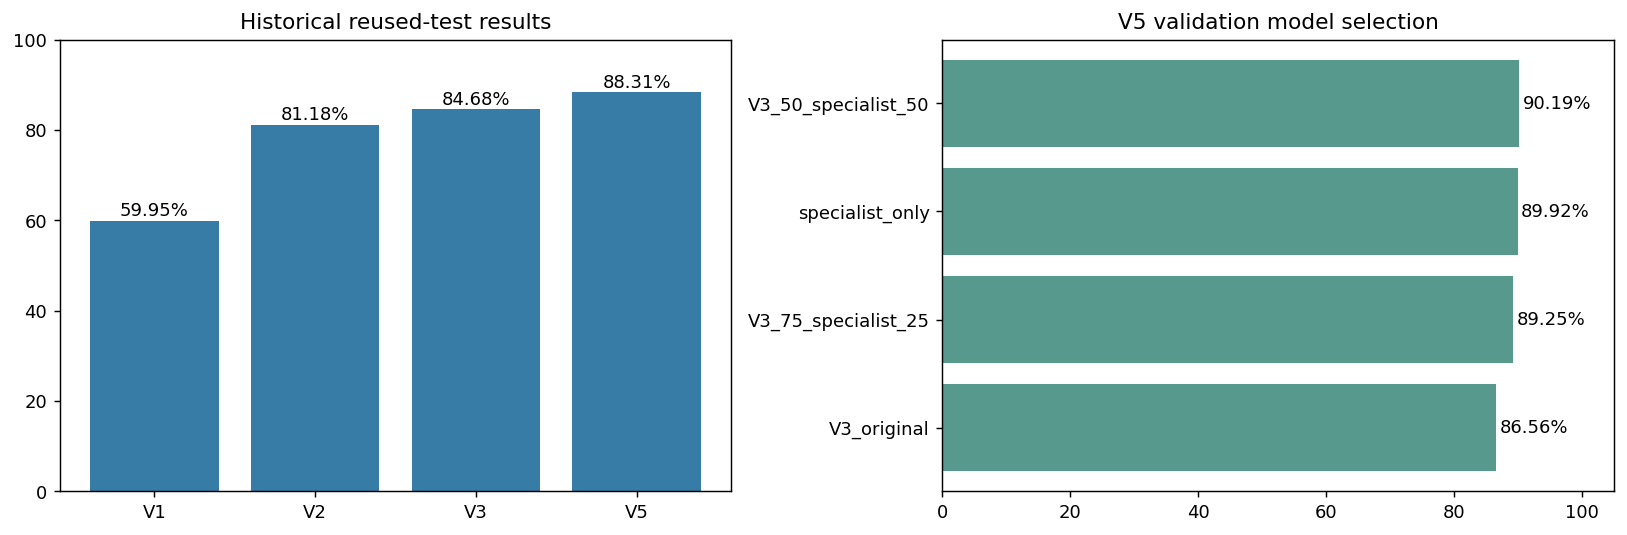

In [ ]:
# نرسم أرقام التجارب المحفوظة، مع تمييز Validation عن Test
history_test=[('V1',59.95),('V2',81.18),('V3',84.6774193548387),('V5',metrics['test_if_run']['accuracy']*100)]
fig,axs=plt.subplots(1,2,figsize=(12.4,4))
bars=axs[0].bar([a for a,b in history_test],[b for a,b in history_test])
for bar,(_,val) in zip(bars,history_test):
    axs[0].text(bar.get_x()+bar.get_width()/2,val+1,f'{val:.2f}%',ha='center')
axs[0].set_ylim(0,100);axs[0].set_title('Historical test accuracy (reused test)')
val=candidates.sort_values('validation_accuracy')
bars=axs[1].barh(val['mode'],val['validation_accuracy']*100)
for bar,pct in zip(bars,val['validation_accuracy']*100):
    axs[1].text(pct+0.3,bar.get_y()+bar.get_height()/2,f'{pct:.2f}%',va='center')
axs[1].set_xlim(0,100);axs[1].set_title('V5 validation candidate selection')
fig.tight_layout();fig.savefig(FIGDIR/'06_model_improvements.png',dpi=155);plt.show()
print('V5 test:',metrics['test_if_run']['correct'],'/',metrics['test_if_run']['samples'],
      '| Macro-F1:',round(metrics['test_if_run']['macro_f1'],4))
print('SVM vs KNN on inner training hold-out:')
display(pd.DataFrame(metrics['inner_training_comparison']))

## 09. مصنّف الميزات وتقليل الأبعاد

فحص مكوّن PCA ومصنّف SVM المحفوظين ونوع المصنّف وأبعاد الميزات.

*مؤشر فني:* المعالجة الفعلية: ميزات CNN ثم PCA ثم مصنّف SVM.

In [ ]:
# فحص المصنف الذي دُرّب سابقاً؛ لا تُغير أوزان الشبكات عند تحميله
learned=joblib.load(WORK/'v5_classifier.joblib')
pca=learned['reducer'];svm=learned['classifier']
print('Feature classifier:',learned.get('method',type(svm).__name__))
print('PCA components:',pca.n_components_)
print('SVM kernel:',getattr(svm,'kernel','unknown'))
print('SVM support vectors:',getattr(svm,'support_vectors_',np.empty((0,0))).shape[0])
print('Architecture:', '2×1280 → 2560 → 128 (PCA) → 31 (SVM)')
print('Fine-Tuning illustration: pretrained CNN → freeze early blocks → unfreeze last blocks → train at LR ~1e-5')
print('Fine-Tuning disabled in this presentation; saved model weights will not change.')

## 10. سلامة المخرجات وقابلية التكرار

فحص وجود ملفات النماذج والتسميات وإعدادات الاستدلال وحساب بصمات SHA-256.

*مؤشر فني:* البصمة تكشف تغيّر الملف، ولا تثبت وحدها تكافؤ نتائج التدريب.

In [ ]:
# فحص إمكانية إعادة التحميل، مع بصمات SHA-256 لمراجعة سلامة الملفات
check=[]
for name in ['model_0.keras','model_1.keras','v5_classifier.joblib','labels.json','inference_config.json']:
    p=WORK/name
    check.append({'File':name,'MiB':round(p.stat().st_size/2**20,3),
                  'SHA256 first 12':hashlib.sha256(p.read_bytes()).hexdigest()[:12]})
display(pd.DataFrame(check))
print('التحميل تم مع compile=False لأن التنبؤ لا يحتاج optimizer أو إعادة compile.')

## 11. الاستدلال على صورة جديدة

تطبيق معالجة RGB وإعادة التحجيم واستخراج الميزات وتوقعات SVM والدمج النهائي.

*مؤشر فني:* المعالجة في الاستدلال يجب أن تطابق المعالجة التي بُني عليها التصنيف.

In [ ]:
# خط أنابيب الاستدلال الفعلي: CNNs → PCA → SVM → ensemble
extractors=[tf.keras.Model(m.inputs,[m.get_layer('global_average_pooling2d').output,m.outputs[0]])
            for m in models]

def predict_v5(pil_image):
    rgb=np.asarray(ImageOps.exif_transpose(pil_image).convert('RGB'),dtype=np.float32)
    embeddings=[]; cnns=[]
    for extractor,size in zip(extractors,config['image_sizes']):
        x=tf.image.resize_with_pad(tf.convert_to_tensor(rgb),int(size[0]),int(size[1]))
        feature,prob=extractor.predict(x[None,...],verbose=0)
        embeddings.append(normalize(feature.astype('float32')))
        cnns.append(prob[0])
    base=.5*cnns[0]+.5*cnns[1]
    joined=np.concatenate(embeddings,axis=1)
    spec=svm.predict_proba(pca.transform(joined))[0]
    mode=config['mode']
    if mode=='V3_50_specialist_50': scores=.5*base+.5*spec
    elif mode=='V3_75_specialist_25': scores=.75*base+.25*spec
    elif mode=='specialist_only': scores=spec
    elif mode=='V3_original': scores=base
    else: raise ValueError('وضع غير معروف: '+str(mode))
    return scores

if extra_images:
    pic=Image.open(extra_images[0]);score=predict_v5(pic)
    top=np.argsort(score)[::-1][:5]
    fig,axs=plt.subplots(1,2,figsize=(10,3.6))
    axs[0].imshow(ImageOps.exif_transpose(pic).convert('RGB'));axs[0].axis('off');axs[0].set_title('Input photo')
    axs[1].barh(np.arange(5),score[top][::-1]*100)
    axs[1].set_yticks(np.arange(5),[classes[i] for i in top[::-1]])
    axs[1].set_xlabel('Model score %');axs[1].set_title('Top-5 predicted classes')
    fig.tight_layout();fig.savefig(FIGDIR/'07_demo_prediction.png',dpi=155);plt.show()
    print('Top prediction:',ar.get(classes[top[0]],classes[top[0]]),f'({score[top[0]]*100:.1f}%)')
else:
    print('لم تُرفق صورة اختبار — تجاوز العرض الاختياري دون إيقاف بقية الدفتر.')

## 12. حفظ الرسومات والتقارير

تجميع مخططات العرض الناتجة في ملف مضغوط منفصل قابل للأرشفة.

*مؤشر فني:* لا تُعدل هذه الخطوة الأوزان أو نتائج التقييم.

In [ ]:
# حفظ الرسومات المنتجة في ملف ZIP، بدون تنزيل تلقائي قد يقطع العرض
import shutil
zip_base=WORK/'ArSL_V5_Defense_Charts'
package=shutil.make_archive(str(zip_base),'zip',root_dir=FIGDIR)
print('اكتمل العرض. الرسومات:',len(list(FIGDIR.glob('*.png'))))
print('ملف الرسومات:',package)
print('المشروع المعتمد: V5 | Accuracy:',f"{metrics['test_if_run']['accuracy']*100:.2f}%",
      '| Validation:',f"{metrics['v5_validation_accuracy']*100:.2f}%")

---
## الملحق الفني: شيفرة بناء النموذج المعتمد

يضم الملحق الخلايا الأصلية اللازمة لتتبع البيانات، واستخراج الميزات، وتدريب المصنّف، والاختيار والتصدير. الشيفرات معروضة مرجعياً ولا تُنفّذ ضمن خلايا العرض.

<details>
<summary><strong>01. تثبيت الاعتماديات — الشيفرة الأصلية</strong></summary>

```python
%pip -q install kagglehub scikit-learn pandas pillow joblib gradio
```

</details>

*تجهيز الأدوات القياسية المستخدمة في تنزيل الصور وتجهيزها والتصنيف وإخراج الرسوم.*

<details>
<summary><strong>02. تهيئة بيئة التدريب — الشيفرة الأصلية</strong></summary>

```python
import os, json, zipfile, hashlib, shutil, gc, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
import joblib
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from google.colab import drive, files
from IPython.display import display

SEED=42
np.random.seed(SEED);random.seed(SEED);tf.random.set_seed(SEED)
drive.mount('/content/drive')
BASE=Path('/content/drive/MyDrive')
V3=BASE/'ArSL_V3_Accuracy_Improvement'/'Final_ArSL_V3'
V5=BASE/'ArSL_V5_Feature_Classification';V5.mkdir(parents=True,exist_ok=True)
WORK=Path('/content/arsl_v5_work');WORK.mkdir(parents=True,exist_ok=True)
DATA_ROOT_OVERRIDE='' # مسار الصور في Drive /content إذا كانت موجودة، لتجنب التنزيل
BATCH=32
RUN_EXPLORATORY_TEST=True   # لن يستخدم الاختبار للاختيار، ويمكن تغييره إلى False
print('TensorFlow:',tf.__version__, '| GPU:',tf.config.list_physical_devices('GPU'))
print('كل نتائجنا ستُحفظ في:',V5)
```

</details>

*ضبط البذور العشوائية ومسارات الملفات وبيئة TensorFlow والتخزين.*

<details>
<summary><strong>03. استعادة خط الأساس والتقسيم — الشيفرة الأصلية</strong></summary>

```python
required={'model_0.keras','model_1.keras','labels.json','inference_config.json','metrics_v3.json'}
if not all((V3/f).exists() for f in required):
    print('لم أعثر على نماذج V3 في Google Drive. اختر ArSL_V3_Final_Results.zip:')
    upload=files.upload()
    filename='ArSL_V3_Final_Results.zip'
    if filename not in upload:raise FileNotFoundError(filename)
    V3.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile('/content/'+filename) as z:
        assert required.issubset(z.namelist()), 'ملف V3 ناقص'
        for name in required:
            (V3/name).write_bytes(z.read(name))

metadata=json.loads((V3/'labels.json').read_text(encoding='utf-8'))
classes=metadata['class_names']; class_to_id={c:i for i,c in enumerate(classes)}
assert len(classes)==31 and len(set(classes))==31
meta_v3=json.loads((V3/'metrics_v3.json').read_text(encoding='utf-8'))
conf_v3=json.loads((V3/'inference_config.json').read_text(encoding='utf-8'))
assert conf_v3['mode']=='ensemble' and len(conf_v3['members'])==2
assert abs(sum(m['weight'] for m in conf_v3['members'])-1)<1e-8
print('نسخة V3 الأصلية موجودة. أسماء الفئات:',len(classes))

old_zip=BASE/'ArSL_Accuracy_Improvement'/'Arabic_Sign_DL_Results.zip'
if not old_zip.exists():old_zip=Path('/content/Arabic_Sign_DL_Results.zip')
if not old_zip.exists():
    print('ارفع الملف الأول Arabic_Sign_DL_Results.zip للحصول على التقسيم الثابت:')
    upload=files.upload()
    if 'Arabic_Sign_DL_Results.zip' not in upload:raise FileNotFoundError('Arabic_Sign_DL_Results.zip')
    old_zip=Path('/content/Arabic_Sign_DL_Results.zip')
with zipfile.ZipFile(old_zip) as z:
    assert 'split_manifest.csv' in z.namelist()
    (WORK/'split_manifest.csv').write_bytes(z.read('split_manifest.csv'))
manifest=pd.read_csv(WORK/'split_manifest.csv')
assert set(manifest.columns)>={'path','label_id','split'}
assert manifest.split.value_counts().to_dict()=={'train':3472,'val':744,'test':744}
manifest['key']=[(Path(str(p)).parent.name,Path(str(p)).name) for p in manifest.path]
assert not manifest.key.duplicated().any()
print('التقسيم ثابت:',manifest.split.value_counts().to_dict())
```

</details>

*فتح أوزان النماذج السابقة وقائمة الفئات والتقسيم المرجعي الثابت.*

<details>
<summary><strong>04. تحميل البيانات وفحصها — الشيفرة الأصلية</strong></summary>

```python
DATASET='muhammadalbrham/rgb-arabic-alphabets-sign-language-dataset'
root=Path(DATA_ROOT_OVERRIDE) if DATA_ROOT_OVERRIDE else Path(kagglehub.dataset_download(DATASET))
if not root.exists():raise FileNotFoundError(str(root))
def find_class_root(base):
    options=[base]+[p for p in base.rglob('*') if p.is_dir()]
    return max(options,key=lambda d:sum((d/c).is_dir() for c in classes))
class_root=find_class_root(root)
if sum((class_root/c).is_dir() for c in classes)!=31:
    archives=list(root.rglob('*.zip'))
    if not archives:raise RuntimeError('لم نجد مجلدات الفئات؛ اضبط DATA_ROOT_OVERRIDE')
    dest=WORK/'dataset_extracted';dest.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as z:z.extractall(dest)
    class_root=find_class_root(dest)
assert sum((class_root/c).is_dir() for c in classes)==31
exts={'.jpg','.jpeg','.png','.bmp'}
all_paths=sorted(p for c in classes for p in (class_root/c).iterdir() if p.is_file() and p.suffix.lower() in exts)
by_key={(p.parent.name,p.name):p for p in all_paths}
assert len(by_key)==len(all_paths)
missing=[k for k in manifest.key if k not in by_key]
if missing:raise FileNotFoundError(f'بيانات التقسيم القديم غير موجودة: {missing[:5]}')
for rec in manifest.itertuples(index=False):
    assert class_to_id[rec.key[0]]==int(rec.label_id),'التسميات غير متطابقة'

seen={hashlib.sha256(by_key[k].read_bytes()).hexdigest() for k in manifest.key}
old_keys=set(manifest.key)
extras=[]; duplicates=0; invalid=0
for path in all_paths:
    key=(path.parent.name,path.name)
    if key in old_keys:continue
    try:
        with Image.open(path) as im:im.verify()
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
    except Exception:invalid+=1;continue
    if digest in seen:duplicates+=1;continue
    seen.add(digest);extras.append(path)

def split(name):
    frame=manifest.loc[manifest.split==name]
    return [str(by_key[k]) for k in frame.key],frame.label_id.to_numpy(np.int32)
train_paths,train_y=split('train'); val_paths,val_y=split('val'); test_paths,test_y=split('test')
train_paths.extend(str(p) for p in extras)
train_y=np.concatenate([train_y,np.array([class_to_id[p.parent.name] for p in extras],np.int32)])
assert (len(train_y),len(val_y),len(test_y))==(6165,744,744)
assert not (set(train_paths)&set(val_paths) or set(train_paths)&set(test_paths) or set(val_paths)&set(test_paths))
print('صور التدريب/التحقق/الاختبار:',len(train_y),len(val_y),len(test_y))
print('مضاف للتدريب فقط:',len(extras),'| مستبعدة مكررة:',duplicates,'| تالفة:',invalid)
print('تنبيه: الفصل هنا على مستوى الصورة وليس على مستوى الشخص.')
```

</details>

*قراءة صور AASL والتحقق من قابلية فك الترميز واستبعاد الصور البايتية المكررة.*

<details>
<summary><strong>05. إعداد البيانات واستخراج الميزات — الشيفرة الأصلية</strong></summary>

```python
AUTOTUNE=tf.data.AUTOTUNE

def image_ds(paths,labels,size):
    ds=tf.data.Dataset.from_tensor_slices((list(map(str,paths)),np.asarray(labels,dtype=np.int32)))
    def parse(path,y):
        im=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
        im.set_shape((None,None,3))
        x=tf.image.resize_with_pad(tf.cast(im,tf.float32),*size)
        return x,y
    return ds.map(parse,num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

def data_signature():
    h=hashlib.sha256(b'arsl_v5_feature_1')
    for m in conf_v3['members']:
        h.update(hashlib.sha256((V3/m['file']).read_bytes()).digest())
    for p,y in zip(train_paths,train_y):
        h.update(f'{Path(p).parent.name}/{Path(p).name}|{int(y)}\n'.encode())
    for p,y in zip(val_paths,val_y):
        h.update(f'V/{Path(p).parent.name}/{Path(p).name}|{int(y)}\n'.encode())
    return h.hexdigest()
SIGNATURE=data_signature()
CACHE=V5/'feature_cache_v5.npz'
if CACHE.exists():
    try:
        c=np.load(CACHE,allow_pickle=False)
        if str(c['signature'].item())!=SIGNATURE:raise ValueError('بصمة ملفات البيانات أو النماذج تغيرت')
        features_train=[c['train_0'],c['train_1']]
        features_val=[c['val_0'],c['val_1']]
        val_probs=[c['prob_0'],c['prob_1']]
        assert len(features_train[0])==6165 and len(features_val[0])==744
        print('تم تحميل الميزات المحفوظة في Drive. لا حاجة لتكرار استخراج CNN.')
        cached=True
    except Exception as e:
        print('إهمال ذاكرة ميزات قديمة:',e);cached=False
else:cached=False

if not cached:
    features_train=[];features_val=[];val_probs=[]
    for i,member in enumerate(conf_v3['members']):
        mdl=tf.keras.models.load_model(V3/member['file'],compile=False)
        assert tuple(mdl.input_shape[1:3])==tuple(member['size'])
        extractor=tf.keras.Model(mdl.inputs,[mdl.get_layer('global_average_pooling2d').output,mdl.outputs[0]])
        print(f'استخرج ميزات الشبكة {i+1}/2 من Train...')
        f_train,_=extractor.predict(image_ds(train_paths,train_y,tuple(member['size'])),verbose=1)
        print(f'استخرج ميزات الشبكة {i+1}/2 من Validation...')
        f_val,p_val=extractor.predict(image_ds(val_paths,val_y,tuple(member['size'])),verbose=1)
        features_train.append(np.asarray(f_train,dtype=np.float32))
        features_val.append(np.asarray(f_val,dtype=np.float32))
        val_probs.append(np.asarray(p_val,dtype=np.float32))
        del mdl,extractor;tf.keras.backend.clear_session();gc.collect()
    np.savez_compressed(CACHE,signature=np.array(SIGNATURE),
                        train_0=features_train[0],train_1=features_train[1],
                        val_0=features_val[0],val_1=features_val[1],
                        prob_0=val_probs[0],prob_1=val_probs[1])
    print('حُفظت الميزات:',CACHE)

assert all(x.shape[0]==6165 for x in features_train)
assert all(x.shape[0]==744 for x in features_val)
base_val=(val_probs[0]+val_probs[1])/2
base_correct=int(np.sum(base_val.argmax(1)==val_y))
expected=int(meta_v3['validation_accuracy']*744+0.5)
print('إعادة إنتاج V3:',base_correct,'/',len(val_y),'| المتوقع:',expected)
if base_correct!=644 or expected!=644:
    raise RuntimeError('❌ لم تتطابق نتيجة V3؛ افحص معالجة الصور وترتيب الفئات قبل المتابعة.')
```

</details>

*تهيئة TensorFlow Dataset واستخراج الميزات وتوقعات الشبكات وحفظ نتائج المرور.*

<details>
<summary><strong>06. تدريب PCA والمصنّف — الشيفرة الأصلية</strong></summary>

```python
def fuse(a,b):
    return np.concatenate((normalize(a.astype('float32')),normalize(b.astype('float32'))),axis=1).astype('float32')
Xtr=fuse(*features_train)
Xval=fuse(*features_val)
tr_idx,inner_idx=train_test_split(np.arange(len(train_y)),test_size=0.15,random_state=SEED,stratify=train_y)
X_inner_train=Xtr[tr_idx]; X_inner_eval=Xtr[inner_idx]
y_inner_train=train_y[tr_idx];y_inner_eval=train_y[inner_idx]

inner_pca=PCA(n_components=128,svd_solver='randomized',random_state=SEED)
Zinner_train=inner_pca.fit_transform(X_inner_train)
Zinner_eval=inner_pca.transform(X_inner_eval)
models={
    'SVM_RBF':SVC(C=4.0,kernel='rbf',gamma='scale',probability=True,random_state=SEED,cache_size=400),
    'KNN_Cosine':KNeighborsClassifier(n_neighbors=9,weights='distance',metric='cosine'),
}
internal_rows=[]
for name,candidate in models.items():
    print('تدريب',name)
    candidate.fit(Zinner_train,y_inner_train)
    inner_predictions=candidate.predict(Zinner_eval)
    internal_rows.append({'method':name,'inner_accuracy':float(accuracy_score(y_inner_eval,inner_predictions)),
                          'inner_macro_f1':float(f1_score(y_inner_eval,inner_predictions,average='macro'))})
internal_table=pd.DataFrame(internal_rows).sort_values(['inner_accuracy','inner_macro_f1'],ascending=False)
display(internal_table)
chosen_method=internal_table.iloc[0]['method']
print('اختيار داخلي من TRAIN فقط:',chosen_method)

del models,inner_pca,Zinner_train,Zinner_eval
# إعادة ملاءمة الميزات والمصنّف على جميع صور Train، دون Val أو Test
reducer=PCA(n_components=128,svd_solver='randomized',random_state=SEED)
Ztr=reducer.fit_transform(Xtr)
Zval=reducer.transform(Xval)
if chosen_method=='SVM_RBF':
    specialist=SVC(C=4.0,kernel='rbf',gamma='scale',probability=True,random_state=SEED,cache_size=400)
else:
    specialist=KNeighborsClassifier(n_neighbors=9,weights='distance',metric='cosine')
specialist.fit(Ztr,train_y)
assert np.array_equal(specialist.classes_,np.arange(31))
spec_val=np.asarray(specialist.predict_proba(Zval),dtype=np.float32)
assert spec_val.shape==(744,31) and np.isfinite(spec_val).all()
print('تم تدريب',chosen_method,'على 6165 صورة. دقة المصنف منفرداً على Validation:',f'{accuracy_score(val_y,spec_val.argmax(1)):.2%}')
```

</details>

*جمع تمثيلات الشبكتين وتطبيعها وتقليل الأبعاد ومقارنة SVM وKNN.*

<details>
<summary><strong>07. الاختيار باستخدام التحقق — الشيفرة الأصلية</strong></summary>

```python
val_variants={
    'V3_original':base_val,
    'specialist_only':spec_val,
    'V3_75_specialist_25':0.75*base_val+0.25*spec_val,
    'V3_50_specialist_50':0.50*base_val+0.50*spec_val,
}
rows=[]
for name,p in val_variants.items():
    rows.append({'mode':name,'correct':int(np.sum(p.argmax(1)==val_y)),
                 'validation_accuracy':float(accuracy_score(val_y,p.argmax(1))),
                 'macro_f1':float(f1_score(val_y,p.argmax(1),average='macro'))})
validation_table=pd.DataFrame(rows).sort_values(['correct','macro_f1'],ascending=False)
display(validation_table)
champion=validation_table.iloc[0]
GAIN_MIN=6
mode=str(champion['mode']) if int(champion['correct']) >= base_correct+GAIN_MIN else 'V3_original'
accepted=mode!='V3_original'
chosen_val=val_variants[mode]
print('V3:',base_correct,'/',len(val_y), '=>',f'{base_correct/744:.2%}')
print('قرار V5:',mode,'| الصحيح:',int(np.sum(chosen_val.argmax(1)==val_y)),'/',len(val_y), '| اعتمد:',accepted)
print('نقطة مهمة: لا نختار شيئاً بناء على Test.')

class_rows=[]
for c,name in enumerate(classes):
    ix=np.flatnonzero(val_y==c)
    class_rows.append({'class':name,'arabic':metadata['arabic_labels'].get(name,name),
                       'samples':len(ix),'V3_correct':int((base_val[ix].argmax(1)==val_y[ix]).sum()),
                       'V5_correct':int((chosen_val[ix].argmax(1)==val_y[ix]).sum())})
class_table=pd.DataFrame(class_rows)
class_table['difference']=class_table.V5_correct-class_table.V3_correct
print('مقارنة الفئات الأكثر تأثراً:')
display(class_table.sort_values('difference').head(8))
display(class_table.sort_values('difference',ascending=False).head(8))
```

</details>

*مقارنة أداء التصنيفات الفردية والمُدمجة وفق معيار قرار معرف مسبقاً.*

<details>
<summary><strong>08. التقييم الاستكشافي — الشيفرة الأصلية</strong></summary>

```python
result_test=None
if RUN_EXPLORATORY_TEST and accepted:
    test_features=[];test_probs=[]
    for i,m in enumerate(conf_v3['members']):
        mdl=tf.keras.models.load_model(V3/m['file'],compile=False)
        extractor=tf.keras.Model(mdl.inputs,[mdl.get_layer('global_average_pooling2d').output,mdl.outputs[0]])
        f,p=extractor.predict(image_ds(test_paths,test_y,tuple(m['size'])),verbose=1)
        test_features.append(np.asarray(f,dtype=np.float32))
        test_probs.append(np.asarray(p,dtype=np.float32))
        del mdl,extractor;tf.keras.backend.clear_session();gc.collect()
    base_test=(test_probs[0]+test_probs[1])/2
    base_test_correct=int(np.sum(base_test.argmax(1)==test_y))
    assert base_test_correct==630, f'اختبار V3 لم يُستعد كما هو: {base_test_correct} بدلاً من 630'
    spec_test=specialist.predict_proba(reducer.transform(fuse(*test_features)))
    if mode=='specialist_only': p_test=spec_test
    elif mode=='V3_75_specialist_25':p_test=0.75*base_test+0.25*spec_test
    elif mode=='V3_50_specialist_50':p_test=0.50*base_test+0.50*spec_test
    else:raise RuntimeError('mode غير معروف')
    result_test={'accuracy':float(accuracy_score(test_y,p_test.argmax(1))),
                 'macro_f1':float(f1_score(test_y,p_test.argmax(1),average='macro')),
                 'correct':int(np.sum(p_test.argmax(1)==test_y)),
                 'samples':len(test_y),'status':'exploratory_reused_test'}
    print('V3 تاريخياً:',base_test_correct,'/',len(test_y),f'({base_test_correct/len(test_y):.2%})')
    print('V5 استكشافي:',result_test['correct'],'/',len(test_y),f"({result_test['accuracy']:.2%})")
    print('لا نعتمد التعديل أو نلغيه بناءً على هذه النتائج؛ القرار ثُبّت باستخدام Validation.')
else:
    print('لم يُجرَ اختبار جديد لأننا أبقينا V3، أو لأن RUN_EXPLORATORY_TEST=False.')
```

</details>

*تقييم إعداد المصنّف بعد تثبيت قرار Validation وعدم الضبط على Test.*

<details>
<summary><strong>09. تصدير النموذج والتقارير — الشيفرة الأصلية</strong></summary>

```python
OUT=V5/'Final_V5_Deployment';OUT.mkdir(parents=True,exist_ok=True)
for name in ['model_0.keras','model_1.keras','labels.json']:
    if not (OUT/name).exists() or (OUT/name).stat().st_size!=(V3/name).stat().st_size:
        shutil.copy2(V3/name,OUT/name)
joblib.dump({'reducer':reducer,'classifier':specialist,'method':chosen_method},OUT/'v5_classifier.joblib',compress=3)
config={'mode':mode,'accepted_on_validation':accepted,'class_count':31,
        'image_sizes':[m['size'] for m in conf_v3['members']],
        'reference_v3_weights':[m['weight'] for m in conf_v3['members']],
        'input':'RGB 0..255, resize_with_pad; CNN internal preprocessing',
        'warning':'score is not a guarantee for unknown people; probability estimates can be imperfect'}
(OUT/'inference_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
results={'V3_historical_test_accuracy':float(meta_v3['new_test_accuracy']),
         'V3_validation_accuracy':float(meta_v3['validation_accuracy']),
         'v5_validation_accuracy':float(accuracy_score(val_y,chosen_val.argmax(1))),
         'v5_validation_correct':int(np.sum(chosen_val.argmax(1)==val_y)),
         'baseline_validation_correct':base_correct,
         'inner_training_comparison':internal_rows,'classifier_method':chosen_method,
         'decision':mode,'accepted':accepted,'test_if_run':result_test,
         'limitations':['same image-level split, signer identities are not disjoint',
                        'existing validation/test were reused in prior projects; report as exploratory',
                        'a new person-disjoint set is necessary for trustworthy generalization']}
(OUT/'metrics_v5.json').write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding='utf-8')
validation_table.to_csv(OUT/'validation_candidates.csv',index=False)
class_table.to_csv(OUT/'class_comparison.csv',index=False)
(OUT/'requirements.txt').write_text('tensorflow>=2.16,<3\nnumpy>=1.26\nscikit-learn>=1.4\njoblib>=1.3\nPillow>=10\ngradio>=5,<7\n',encoding='utf-8')
print('حُفظت نتائج V5:',OUT)
```

</details>

*حفظ الأوزان والمصنّف والتسميات والإعدادات وتقارير النتائج.*

<details>
<summary><strong>10. بناء واجهة الاستدلال — الشيفرة الأصلية</strong></summary>

```python
APP = '''"""ArSL V5 -- ensemble or learned-feature classifier, images only."""
from pathlib import Path
import json, numpy as np, tensorflow as tf, joblib
from PIL import Image, ImageOps
from sklearn.preprocessing import normalize
import gradio as gr

ROOT=Path(__file__).resolve().parent
labels=json.loads((ROOT/'labels.json').read_text(encoding='utf-8'))
classes=labels['class_names']
arabic=labels.get('arabic_labels',{})
config=json.loads((ROOT/'inference_config.json').read_text(encoding='utf-8'))
models=[tf.keras.models.load_model(ROOT/f'model_{i}.keras',compile=False) for i in range(2)]
extractors=[tf.keras.Model(m.inputs,[m.get_layer('global_average_pooling2d').output,m.outputs[0]]) for m in models]
learned=joblib.load(ROOT/'v5_classifier.joblib')
assert all(m.output_shape[-1]==len(classes) for m in models)

def classify(image):
    if image is None:return {},'ارفع صورة لإشارة يد واضحة.'
    rgb=np.asarray(ImageOps.exif_transpose(image).convert('RGB'),dtype=np.float32)
    features=[];predictions=[]
    for e,size in zip(extractors,config['image_sizes']):
        im=tf.image.resize_with_pad(tf.convert_to_tensor(rgb),int(size[0]),int(size[1]))
        feat,probs=e.predict(tf.expand_dims(im,0),verbose=0)
        features.append(feat);predictions.append(probs[0])
    baseline=0.5*predictions[0]+0.5*predictions[1]
    if config['mode']!='V3_original':
        fv=np.concatenate([normalize(f.astype(np.float32)) for f in features],axis=1)
        spec=learned['classifier'].predict_proba(learned['reducer'].transform(fv))[0]
        if config['mode']=='specialist_only':prediction=spec
        elif config['mode']=='V3_75_specialist_25':prediction=0.75*baseline+0.25*spec
        elif config['mode']=='V3_50_specialist_50':prediction=0.5*baseline+0.5*spec
        else:raise ValueError('غير معروف: '+str(config['mode']))
    else:prediction=baseline
    top=np.argsort(prediction)[::-1][:5]
    answer={f'{arabic.get(classes[int(i)],classes[int(i)])} | {classes[int(i)]}':float(prediction[i]) for i in top}
    note='النتائج تقديرات على صور حروف ثابتة فقط، وليست ترجمة للغة الإشارة في الفيديو.'
    return answer,note

app=gr.Interface(
    fn=classify,
    inputs=gr.Image(type='pil',sources=['upload','webcam'],label='ارفع أو التقط صورة اليد'),
    outputs=[gr.Label(label='أقرب 5 حروف',num_top_classes=5),gr.Textbox(label='ملاحظة')],
    title='ArSL — التعرف على حروف لغة الإشارة العربية',
    description='V5: نموذجَا CNN مع مصنف ميزات (إن اجتاز التحسن شرط القبول).'
)
if __name__=='__main__':app.launch(share=True)
'''
(OUT/'app.py').write_text(APP,encoding='utf-8')
archive=shutil.make_archive('/content/ArSL_V5_Final_Results','zip',OUT)
print('حزمة V5:',archive,'\nحجمها MB:',round(Path(archive).stat().st_size/1024**2,2))
print('قرار التحسين:',config['mode'],'| تم القبول:',config['accepted_on_validation'])
print('الحزمة محفوظة أيضاً في Drive:',OUT)
# اختياري: نفذ السطر التالي فقط إذا أردت تحميل الحزمة على جهازك الآن:
# files.download(archive)
```

</details>

*إنشاء واجهة Gradio مع معالجة تطابق خط سير التدريب.*

<details>
<summary><strong>11. تشغيل واجهة العرض — الشيفرة الأصلية</strong></summary>

```python
import importlib.util
spec=importlib.util.spec_from_file_location('arsl_v5_live',OUT/'app.py')
webapp=importlib.util.module_from_spec(spec)
spec.loader.exec_module(webapp)
webapp.app.launch(share=True,debug=False)
```

</details>

*تشغيل صفحة الاستدلال انطلاقاً من النماذج المحفوظة.*